# Retail Inventory Optimization: Category-wise ARIMA & Prophet, Stock Strategy and Tableau Exports

This notebook adds the pieces the capstone report promises but the LightGBM notebook does not contain:

1. **Category-wise ARIMA and Prophet** demand forecasts, evaluated with **MAE, RMSE and MAPE**
2. A **per-category model comparison** (best model chosen by MAPE)
3. **Stock strategy**: safety stock, reorder points, days of cover, and an inventory **backtest** on the hold-out period
4. **Tableau-ready exports** (CSV files and one Excel workbook)

It re-applies the same cleaning rules as the earlier notebook (negative inventory clipped, sales capped at inventory,
region-level then global majority-vote category correction), so it can be run on its own from `sales_data.csv`.

**Assumptions that are NOT in the dataset** (they are inputs, set in the config cell below): supplier lead time,
review period and target service level. Change them to your real values before quoting any reorder-point figure.

In [1]:
import warnings, logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
for _name in ("cmdstanpy", "prophet"):
    logging.getLogger(_name).setLevel(logging.ERROR); logging.getLogger(_name).disabled = True

# ------------------------------- CONFIG -------------------------------
DATA_CANDIDATES = [Path("sales_data.csv"),
                   Path("/kaggle/input/retail-store-inventory-and-demand-forecasting/sales_data.csv")]
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

TARGET = "Units Sold"      # same target as the LightGBM notebook (use "Demand" to forecast the Demand column instead)
TEST_MONTHS = 3            # hold-out window, same rule as the LightGBM notebook (last 3 months)

# --- Stock-policy ASSUMPTIONS (not in the data; replace with real values) ---
LEAD_TIME_DAYS = 7         # supplier lead time
REVIEW_PERIOD_DAYS = 7     # order quantity covers this many days of forecast demand
SERVICE_LEVEL = 0.95       # target cycle service level
# ----------------------------------------------------------------------

DATA_PATH = next(p for p in DATA_CANDIDATES if p.exists())
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
print("Using data:", DATA_PATH)

Importing plotly failed. Interactive plots will not work.


Using data: sales_data.csv


## 1. Load and clean (same rules as the earlier notebook)

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = raw.copy()

# A.1: clip negative inventory, cap sales at inventory
neg_inv = int((df["Inventory Level"] < 0).sum())
sold_gt_inv = int((df["Units Sold"] > df["Inventory Level"]).sum())
df["Inventory Level"] = df["Inventory Level"].clip(lower=0)
df["Units Sold"] = df[["Units Sold", "Inventory Level"]].min(axis=1)

# C.2.1: category majority vote within each Region x Product, then C.4.1: one global category per Product
mode = lambda s: s.mode().iloc[0]
cats_before = df["Category"].nunique()
df["Category"] = df.groupby(["Region", "Product ID"])["Category"].transform(mode)
df["Category"] = df.groupby("Product ID")["Category"].transform(mode)
assert df.groupby("Product ID")["Category"].nunique().max() == 1

print(f"Rows: {len(df):,} | dates: {df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d} ({df['Date'].nunique()} days)")
print(f"Negative inventory rows fixed: {neg_inv} | sales>inventory rows fixed: {sold_gt_inv}")
print(f"Duplicate rows: {int(df.duplicated().sum())} | missing values: {int(df.isna().sum().sum())}")
print("Products per category:", df.groupby("Category")["Product ID"].nunique().to_dict())

Rows: 76,000 | dates: 2022-01-01 to 2024-01-30 (760 days)
Negative inventory rows fixed: 0 | sales>inventory rows fixed: 0
Duplicate rows: 0 | missing values: 0
Products per category: {'Clothing': 5, 'Electronics': 3, 'Furniture': 3, 'Groceries': 8, 'Toys': 1}


## 2. Build category-level daily series and train/test split
One series per category: total `TARGET` across all stores and products per day. The two regressors
(share of rows on promotion, share of rows flagged as epidemic) are used only by the "with regressors" model variants.

In [3]:
daily = (df.groupby(["Date", "Category"])[TARGET].sum().unstack("Category").asfreq("D"))
reg = df.groupby("Date").agg(promo_share=("Promotion", "mean"), epidemic=("Epidemic", "mean")).asfreq("D")
inv_daily = df.groupby(["Date", "Category"])["Inventory Level"].sum().unstack("Category").asfreq("D")
CATEGORIES = list(daily.columns)

split_date = daily.index.max() - pd.DateOffset(months=TEST_MONTHS)
train_idx, test_idx = daily.index[daily.index <= split_date], daily.index[daily.index > split_date]
print(f"Train: {train_idx.min():%Y-%m-%d} to {train_idx.max():%Y-%m-%d} ({len(train_idx)} days)")
print(f"Test : {test_idx.min():%Y-%m-%d} to {test_idx.max():%Y-%m-%d} ({len(test_idx)} days)")
print("Epidemic flag takes values:", sorted(reg['epidemic'].round(2).unique())[:6], "...")
daily.describe().T[["mean", "std", "min", "max"]].round(0)

Train: 2022-01-01 to 2023-10-30 (668 days)
Test : 2023-10-31 to 2024-01-30 (92 days)
Epidemic flag takes values: [np.float64(0.0), np.float64(1.0)] ...


,mean,std,min,max
Category,,,,
Clothing,2239.0,357.0,1193.0,3180.0
Electronics,1333.0,278.0,617.0,2234.0
Furniture,1173.0,273.0,512.0,1849.0
Groceries,3750.0,737.0,1816.0,5689.0
Toys,388.0,121.0,101.0,789.0


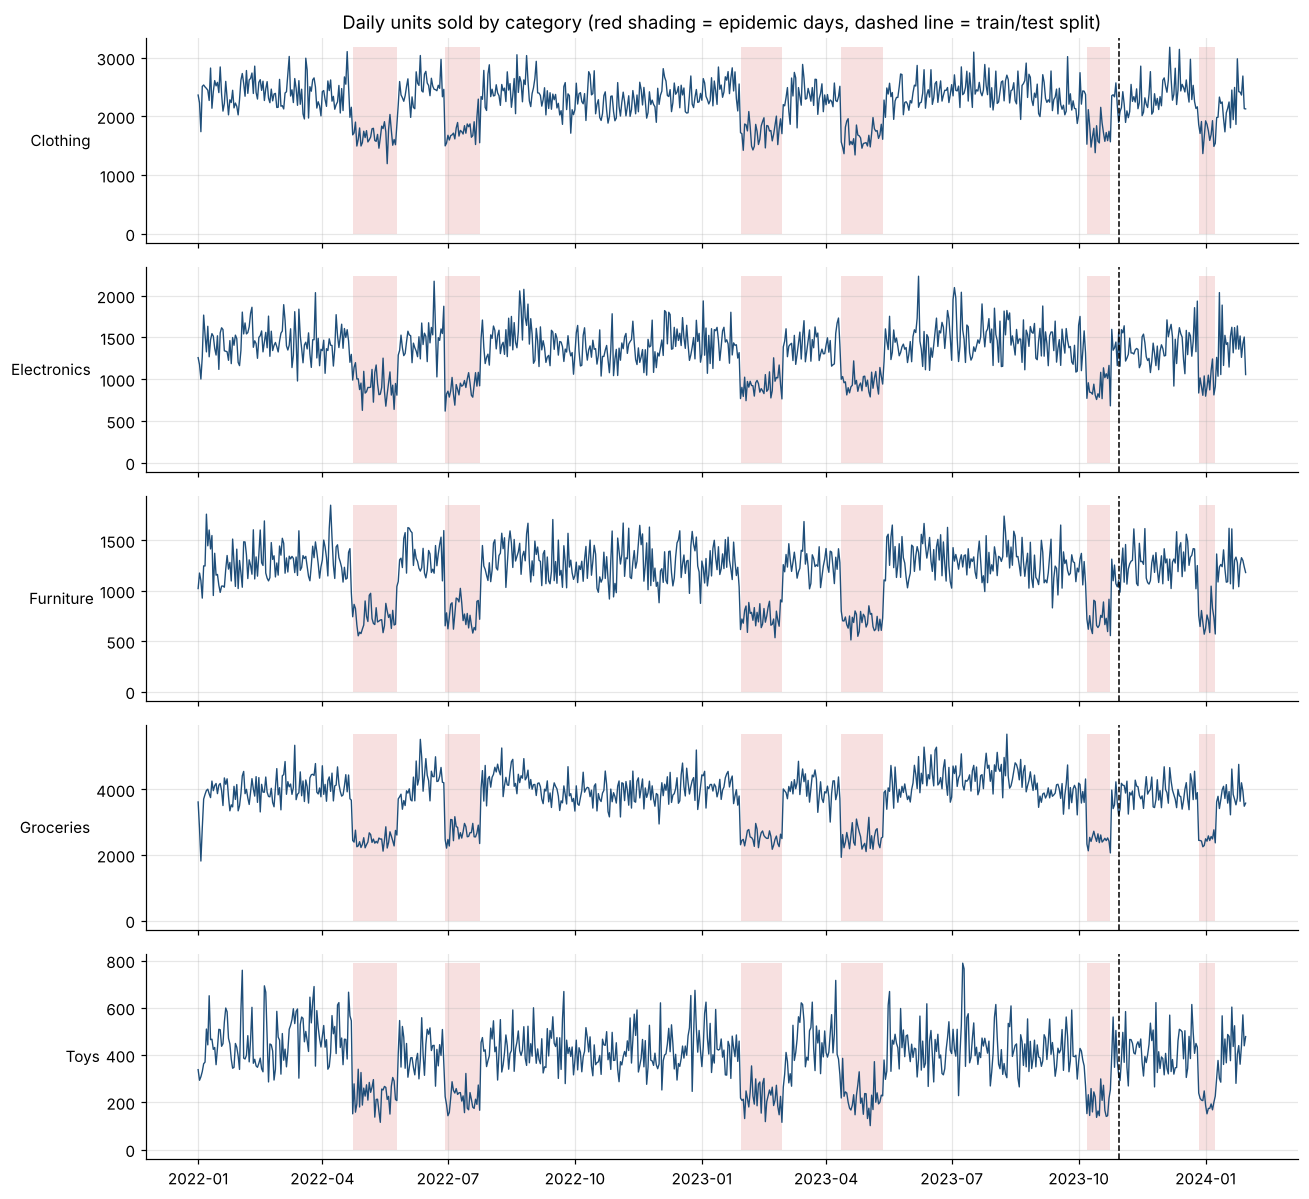

In [4]:
fig, axes = plt.subplots(len(CATEGORIES), 1, figsize=(12, 2.2 * len(CATEGORIES)), sharex=True)
for ax, c in zip(axes, CATEGORIES):
    ax.plot(daily.index, daily[c], lw=0.9, color="#1f4e79")
    ax.fill_between(reg.index, 0, daily[c].max(), where=reg["epidemic"] > 0.5, color="#c00000", alpha=0.12, lw=0)
    ax.axvline(split_date, color="k", ls="--", lw=1)
    ax.set_ylabel(c, rotation=0, ha="right", va="center")
axes[0].set_title("Daily units sold by category (red shading = epidemic days, dashed line = train/test split)")
plt.tight_layout(); plt.show()

## 3. Models
* **Baselines**: two flat forecasts, the mean of the last 28 training days and the mean of the whole training window. A model that cannot beat both adds no value.
* **ARIMA**: order (p,d,q) chosen per category by lowest AIC over p,q in 0-3 and d in {0,1}, fitted on the training window only.
* **Prophet**: trend + weekly seasonality (yearly seasonality is off; there are fewer than two years of data).
* **ARIMAX / Prophet + regressors**: the same models with promotion share and epidemic share as regressors.
  These assume the **future promotion plan and epidemic flag are known** for the forecast window, so read them as scenario-aware models, not as pure forecasts.

In [5]:
def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(np.mean(np.abs((y - yhat) / y)) * 100)

def score(y, yhat):
    return {"MAE": mean_absolute_error(y, yhat),
            "RMSE": float(np.sqrt(mean_squared_error(y, yhat))),
            "MAPE (%)": mape(y, yhat)}

def fit_arima(y_train, exog_train=None, exog_test=None, steps=1):
    best = None
    for d in (0, 1):
        for p in range(4):
            for q in range(4):
                try:
                    res = ARIMA(y_train, exog=exog_train, order=(p, d, q)).fit()
                except Exception:
                    continue
                if best is None or res.aic < best[0]:
                    best = (res.aic, (p, d, q), res)
    aic, order, res = best
    fc = res.forecast(steps=steps, exog=exog_test)
    return np.clip(np.asarray(fc), 0, None), order

def fit_prophet(y_train, exog_train=None, exog_test=None, test_dates=None):
    train = pd.DataFrame({"ds": y_train.index, "y": y_train.values})
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False)
    if exog_train is not None:
        for col in exog_train.columns:
            train[col] = exog_train[col].values
            m.add_regressor(col)
    m.fit(train)
    future = pd.DataFrame({"ds": test_dates})
    if exog_test is not None:
        for col in exog_test.columns:
            future[col] = exog_test[col].values
    return np.clip(m.predict(future)["yhat"].values, 0, None)

In [6]:
EXOG_COLS = ["promo_share", "epidemic"]
forecasts, metric_rows, orders = [], [], {}

for c in CATEGORIES:
    y_tr, y_te = daily.loc[train_idx, c], daily.loc[test_idx, c]
    ex_tr, ex_te = reg.loc[train_idx, EXOG_COLS], reg.loc[test_idx, EXOG_COLS]
    n = len(test_idx)

    preds = {"Baseline: last 28-day mean": np.full(n, y_tr.iloc[-28:].mean()),
             "Baseline: training mean": np.full(n, y_tr.mean())}
    preds["ARIMA"], orders[(c, "ARIMA")] = fit_arima(y_tr, steps=n)
    preds["Prophet"] = fit_prophet(y_tr, test_dates=test_idx)
    preds["ARIMAX (+promo, epidemic)"], orders[(c, "ARIMAX")] = fit_arima(y_tr, ex_tr, ex_te, steps=n)
    preds["Prophet (+promo, epidemic)"] = fit_prophet(y_tr, ex_tr, ex_te, test_idx)

    for model, yhat in preds.items():
        metric_rows.append({"Category": c, "Model": model, **score(y_te, yhat)})
        forecasts.append(pd.DataFrame({"Date": test_idx, "Category": c, "Model": model,
                                       "Actual": y_te.values, "Forecast": yhat}))
    print(f"{c:12s} done | ARIMA order {orders[(c, 'ARIMA')]} | ARIMAX order {orders[(c, 'ARIMAX')]}")

forecast_df = pd.concat(forecasts, ignore_index=True)
metrics = pd.DataFrame(metric_rows)

Clothing     done | ARIMA order (2, 1, 3) | ARIMAX order (0, 1, 1)


Electronics  done | ARIMA order (2, 1, 3) | ARIMAX order (1, 1, 3)


Furniture    done | ARIMA order (2, 1, 3) | ARIMAX order (1, 1, 2)


Groceries    done | ARIMA order (0, 1, 1) | ARIMAX order (0, 1, 1)


Toys         done | ARIMA order (2, 0, 1) | ARIMAX order (1, 1, 1)


## 4. Model evaluation: MAE, RMSE, MAPE per category
The report's headline comparison is **ARIMA vs Prophet**. Best model per category is the lowest MAPE among the two pure time-series models;
the baseline and regressor variants are shown alongside for context.

In [7]:
MODEL_ORDER = ["Baseline: last 28-day mean", "Baseline: training mean", "ARIMA", "Prophet",
               "ARIMAX (+promo, epidemic)", "Prophet (+promo, epidemic)"]
fmt = {"MAE": "{:,.1f}", "RMSE": "{:,.1f}", "MAPE (%)": "{:.2f}"}
display_tbl = metrics.copy()
display_tbl["Model"] = pd.Categorical(display_tbl["Model"], MODEL_ORDER, ordered=True)
display_tbl = display_tbl.sort_values(["Category", "Model"]).reset_index(drop=True)
display(display_tbl.style.format(fmt).background_gradient(subset=["MAPE (%)"], cmap="Blues_r"))

core = metrics[metrics["Model"].isin(["ARIMA", "Prophet"])]
best = core.loc[core.groupby("Category")["MAPE (%)"].idxmin(), ["Category", "Model", "MAE", "RMSE", "MAPE (%)"]].reset_index(drop=True)
best = best.rename(columns={"Model": "Best model (ARIMA vs Prophet)"})
print("\nBest of ARIMA vs Prophet per category (lowest MAPE):")
display(best.style.format(fmt))

,Category,Model,MAE,RMSE,MAPE (%)
0,Clothing,Baseline: last 28-day mean,381.2,468.0,16.10
1,Clothing,Baseline: training mean,267.0,348.3,12.53
2,Clothing,ARIMA,278.8,361.0,12.49
3,Clothing,Prophet,266.4,348.5,12.46
4,Clothing,"ARIMAX (+promo, epidemic)",207.3,266.2,9.33
5,Clothing,"Prophet (+promo, epidemic)",219.9,275.4,10.07
6,Electronics,Baseline: last 28-day mean,302.1,361.9,21.26
7,Electronics,Baseline: training mean,202.0,255.6,16.49
8,Electronics,ARIMA,205.1,258.1,17.00
9,Electronics,Prophet,203.9,257.6,16.78



Best of ARIMA vs Prophet per category (lowest MAPE):


,Category,Best model (ARIMA vs Prophet),MAE,RMSE,MAPE (%)
0,Clothing,Prophet,266.4,348.5,12.46
1,Electronics,Prophet,203.9,257.6,16.78
2,Furniture,Prophet,203.9,252.3,19.61
3,Groceries,Prophet,430.2,606.3,13.85
4,Toys,Prophet,90.5,112.1,27.15


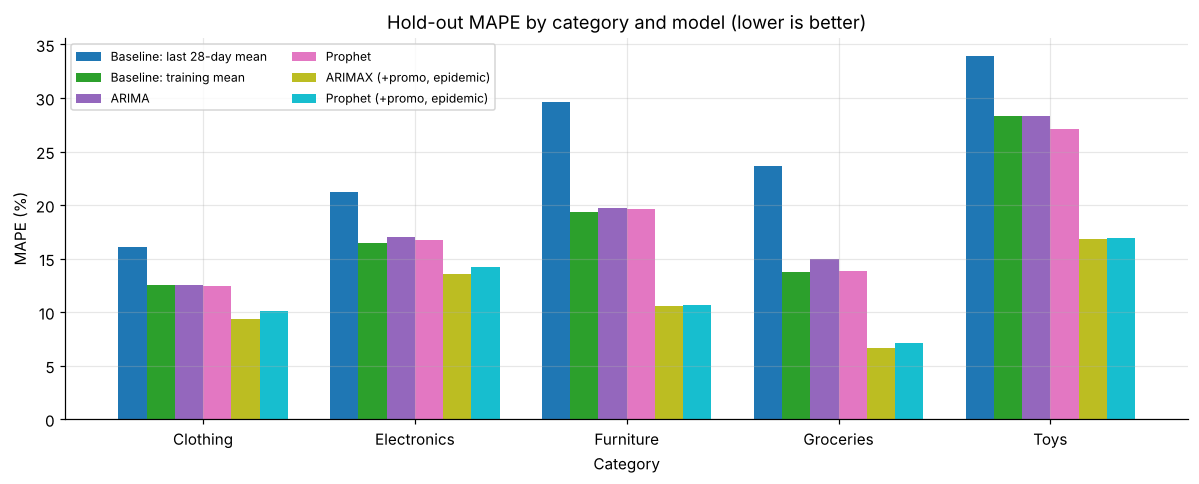

In [8]:
pivot = metrics.pivot(index="Category", columns="Model", values="MAPE (%)")[MODEL_ORDER]
ax = pivot.plot(kind="bar", figsize=(11, 4.5), width=0.8, colormap="tab10")
ax.set_ylabel("MAPE (%)"); ax.set_title("Hold-out MAPE by category and model (lower is better)")
ax.legend(fontsize=8, ncol=2); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

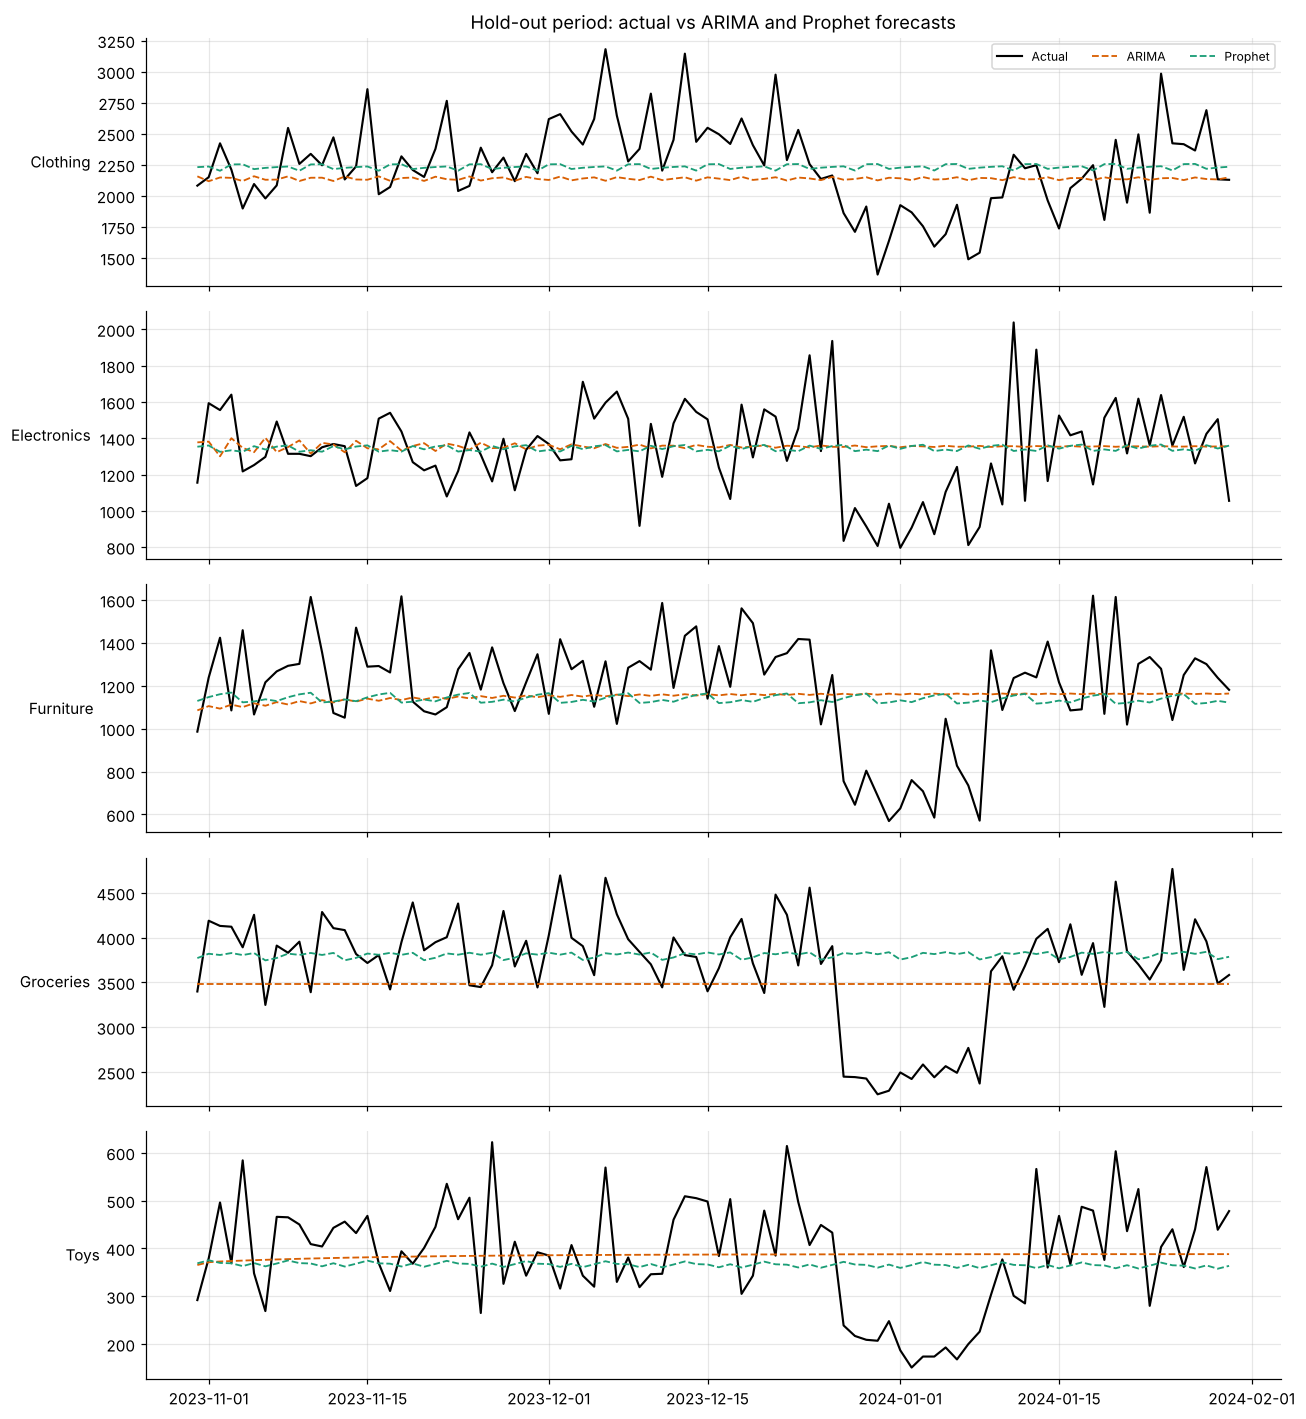

In [9]:
fig, axes = plt.subplots(len(CATEGORIES), 1, figsize=(12, 2.6 * len(CATEGORIES)), sharex=True)
for ax, c in zip(axes, CATEGORIES):
    sub = forecast_df[forecast_df["Category"] == c]
    act = sub[sub["Model"] == "ARIMA"]
    ax.plot(act["Date"], act["Actual"], color="k", lw=1.4, label="Actual")
    for model, col in [("ARIMA", "#d95f02"), ("Prophet", "#1b9e77")]:
        s = sub[sub["Model"] == model]; ax.plot(s["Date"], s["Forecast"], color=col, lw=1.2, ls="--", label=model)
    ax.set_ylabel(c, rotation=0, ha="right", va="center")
axes[0].legend(ncol=3, fontsize=8); axes[0].set_title("Hold-out period: actual vs ARIMA and Prophet forecasts")
plt.tight_layout(); plt.show()

## 5. Stock strategy: safety stock, reorder points and days of cover
Standard formulas, evaluated per category on **training-period** statistics (no test data used):

* Safety stock = z x sigma_daily x sqrt(lead time), with z from the service level and sigma_daily the std-dev of daily category sales in training
* Reorder point = forecast daily demand x lead time + safety stock, using the best ARIMA/Prophet forecast mean for the hold-out window
* Order-up-to level = reorder point + forecast daily demand x review period
* Days of cover = average actual category inventory / average daily sales (from the data; a descriptive overstock indicator)
* Lead time covered by actual inventory = the longest lead time the observed average inventory could cover at the chosen service level.
  This is the one lead-time figure derived from the data rather than assumed; compare it with your real supplier lead time.

In [10]:
z = norm.ppf(SERVICE_LEVEL)
best_model = dict(zip(best["Category"], best["Best model (ARIMA vs Prophet)"]))
policy_rows = []
for c in CATEGORIES:
    y_tr = daily.loc[train_idx, c]
    fc_mean = forecast_df[(forecast_df["Category"] == c) & (forecast_df["Model"] == best_model[c])]["Forecast"].mean()
    sigma = y_tr.std()
    ss = z * sigma * np.sqrt(LEAD_TIME_DAYS)
    rop = fc_mean * LEAD_TIME_DAYS + ss
    policy_rows.append({
        "Category": c, "Best model": best_model[c],
        "Avg daily sales (train)": y_tr.mean(), "Std daily sales (train)": sigma,
        "Forecast avg daily demand": fc_mean, "Safety stock": ss, "Reorder point": rop,
        "Order-up-to level": rop + fc_mean * REVIEW_PERIOD_DAYS,
        "Avg inventory on hand (actual)": inv_daily[c].mean(),
        "Days of cover (actual)": inv_daily[c].mean() / daily[c].mean(),
        "Days of cover at reorder point": rop / fc_mean,
    })
policy = pd.DataFrame(policy_rows)
# Longest lead time (days) that the actual average inventory could cover at the chosen service level:
# solve  d*L + z*sigma*sqrt(L) = inventory  for L.
a, b = policy["Avg daily sales (train)"], z * policy["Std daily sales (train)"]
policy["Lead time covered by actual inventory (days)"] = (((-b + np.sqrt(b**2 + 4 * a * policy["Avg inventory on hand (actual)"])) / (2 * a)) ** 2)
print(f"Assumptions: lead time {LEAD_TIME_DAYS} d | review period {REVIEW_PERIOD_DAYS} d | service level {SERVICE_LEVEL:.0%} (z = {z:.3f})")
display(policy.style.format({c: "{:,.0f}" for c in policy.columns if c not in ["Category", "Best model", "Days of cover (actual)", "Days of cover at reorder point", "Lead time covered by actual inventory (days)"]}
                            | {"Days of cover (actual)": "{:.1f}", "Days of cover at reorder point": "{:.1f}", "Lead time covered by actual inventory (days)": "{:.1f}"}))

Assumptions: lead time 7 d | review period 7 d | service level 95% (z = 1.645)


,Category,Best model,Avg daily sales (train),Std daily sales (train),Forecast avg daily demand,Safety stock,Reorder point,Order-up-to level,Avg inventory on hand (actual),Days of cover (actual),Days of cover at reorder point,Lead time covered by actual inventory (days)
0,Clothing,Prophet,"2,239",358,"2,231","1,560","17,179","32,798","6,334",2.8,7.7,2.4
1,Electronics,Prophet,"1,333",281,"1,344","1,225","10,635","20,046","4,144",3.1,7.9,2.6
2,Furniture,Prophet,"1,171",276,"1,138","1,202","9,167","17,132","4,566",3.9,8.1,3.2
3,Groceries,Prophet,"3,759",754,"3,807","3,280","29,932","56,584","13,936",3.7,7.9,3.1
4,Toys,Prophet,388,122,366,531,"3,091","5,652","1,126",2.9,8.5,2.1


## 6. Inventory backtest on the hold-out window
Day-by-day simulation per category on the hold-out days, with **actual** units sold as demand and lost sales when stock runs out.
Two reorder policies are compared, identical except for the demand estimate they plan with:

* **Forecast policy**: plans with the best model's forecast for the next lead-time window
* **Static policy**: plans with the training-period mean daily sales

Both start the window fully stocked to their order-up-to level and use the same lead time, review period and safety stock.
This is a stylised simulation on category totals; the dataset's own inventory levels are not part of it.

In [11]:
def simulate(demand, mean_plan, ss, lead, review):
    n = len(demand); on_hand = mean_plan[0] * (lead + review) + ss
    pipeline, sold_tot, stockout_days, on_hand_hist = {}, 0.0, 0, []
    for t in range(n):
        on_hand += pipeline.pop(t, 0.0)
        sold = min(on_hand, demand[t]); on_hand -= sold; sold_tot += sold
        stockout_days += int(sold < demand[t])
        position = on_hand + sum(pipeline.values())
        d_hat = mean_plan[t]
        s_pt = d_hat * lead + ss
        if position <= s_pt:
            pipeline[t + lead] = pipeline.get(t + lead, 0.0) + (s_pt + d_hat * review - position)
        on_hand_hist.append(on_hand)
    return {"Fill rate (%)": 100 * sold_tot / demand.sum(), "Stockout days": stockout_days,
            "Avg on-hand units": float(np.mean(on_hand_hist))}

bt_rows = []
for c in CATEGORIES:
    demand = daily.loc[test_idx, c].values
    fc = forecast_df[(forecast_df["Category"] == c) & (forecast_df["Model"] == best_model[c])]["Forecast"].values
    ss = z * daily.loc[train_idx, c].std() * np.sqrt(LEAD_TIME_DAYS)
    fc_plan = np.array([fc[t:t + LEAD_TIME_DAYS].mean() for t in range(len(fc))])
    static_plan = np.full(len(fc), daily.loc[train_idx, c].mean())
    for name, plan in [("Forecast policy", fc_plan), ("Static policy", static_plan)]:
        bt_rows.append({"Category": c, "Policy": name, **simulate(demand, plan, ss, LEAD_TIME_DAYS, REVIEW_PERIOD_DAYS)})
backtest = pd.DataFrame(bt_rows)
display(backtest.style.format({"Fill rate (%)": "{:.1f}", "Avg on-hand units": "{:,.0f}"}))

,Category,Policy,Fill rate (%),Stockout days,Avg on-hand units
0,Clothing,Forecast policy,99.6,2,"11,048"
1,Clothing,Static policy,99.7,1,"11,149"
2,Electronics,Forecast policy,100.0,0,"7,138"
3,Electronics,Static policy,100.0,0,"7,081"
4,Furniture,Forecast policy,100.0,0,"5,733"
5,Furniture,Static policy,100.0,1,"6,079"
6,Groceries,Forecast policy,100.0,0,"20,767"
7,Groceries,Static policy,100.0,0,"20,096"
8,Toys,Forecast policy,100.0,1,"1,939"
9,Toys,Static policy,100.0,0,"2,195"


## 7. KPIs for the dashboard
Stockouts and forecast error are computed from the data. **Wastage % cannot be computed: the dataset has no wastage or write-off field.**
If wastage records exist (the project plan lists them), join them on Date/Store ID/Product ID and add the KPI in Tableau.

In [12]:
store_kpi = (df.assign(Stockout=(df["Units Sold"] >= df["Inventory Level"]).astype(int),
                       Unmet=(df["Demand"] - df["Inventory Level"]).clip(lower=0))
               .groupby(["Store ID", "Category"])
               .agg(Rows=("Date", "size"), Units_Sold=("Units Sold", "sum"), Avg_Inventory=("Inventory Level", "mean"),
                    Stockout_Rows=("Stockout", "sum"), Rows_Demand_Over_Inventory=("Unmet", lambda s: int((s > 0).sum())))
               .reset_index())
store_kpi["Stockout_Rate_%"] = 100 * store_kpi["Stockout_Rows"] / store_kpi["Rows"]
fc_err = (metrics[metrics["Model"].isin(["ARIMA", "Prophet"])]
          .merge(best[["Category", "Best model (ARIMA vs Prophet)"]], left_on=["Category", "Model"],
                 right_on=["Category", "Best model (ARIMA vs Prophet)"])[["Category", "Model", "MAPE (%)"]])
print("Rows where units sold equals inventory (stockout proxy):", int(store_kpi["Stockout_Rows"].sum()),
      "| rows where Demand exceeds inventory:", int(store_kpi["Rows_Demand_Over_Inventory"].sum()))
display(fc_err.rename(columns={"MAPE (%)": "Forecast error rate: best-model MAPE (%)"}).style.format({"Forecast error rate: best-model MAPE (%)": "{:.2f}"}))

Rows where units sold equals inventory (stockout proxy): 8654 | rows where Demand exceeds inventory: 10394


,Category,Model,Forecast error rate: best-model MAPE (%)
0,Clothing,Prophet,12.46
1,Electronics,Prophet,16.78
2,Furniture,Prophet,19.61
3,Groceries,Prophet,13.85
4,Toys,Prophet,27.15


## 8. Tableau-ready exports
* `forecast_long.csv`: one row per Date x Category x Model with Actual and Forecast (forecast-vs-actual trend sheets)
* `model_metrics.csv`, `best_model_by_category.csv`: model comparison sheet
* `inventory_policy.csv`, `backtest_results.csv`: stock-strategy sheets
* `category_daily.csv`: daily sales vs actual inventory by category (inventory vs demand sheet)
* `store_category_kpis.csv`: store-wise filter and KPI sheet
* `tableau_data.xlsx`: all of the above as sheets in one workbook

In [13]:
cat_daily = (daily.stack().rename("Units_Sold").reset_index()
             .merge(inv_daily.stack().rename("Inventory_On_Hand").reset_index(), on=["Date", "Category"])
             .merge(reg.reset_index(), on="Date"))
cat_daily["Is_Test_Period"] = cat_daily["Date"] > split_date

exports = {"forecast_long": forecast_df, "model_metrics": metrics, "best_model_by_category": best,
           "inventory_policy": policy, "backtest_results": backtest, "category_daily": cat_daily,
           "store_category_kpis": store_kpi}
for name, frame in exports.items():
    frame.to_csv(OUT_DIR / f"{name}.csv", index=False)
with pd.ExcelWriter(OUT_DIR / "tableau_data.xlsx", engine="openpyxl", datetime_format="yyyy-mm-dd") as xw:
    for name, frame in exports.items():
        frame.to_excel(xw, sheet_name=name[:31], index=False)
print("Saved:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Saved: backtest_results.csv, best_model_by_category.csv, category_daily.csv, forecast_long.csv, inventory_policy.csv, model_metrics.csv, store_category_kpis.csv, tableau_data.xlsx


## 9. Summary of results (computed from the run above)

In [14]:
base = metrics[metrics["Model"] == "Baseline: training mean"].set_index("Category")["MAPE (%)"]
base28 = metrics[metrics["Model"] == "Baseline: last 28-day mean"].set_index("Category")["MAPE (%)"]
def m(c, model): return metrics[(metrics.Category == c) & (metrics.Model == model)]["MAPE (%)"].iloc[0]
print("Hold-out MAPE (%):")
print(f"  {'':12s} {'ARIMA':>6s} {'Prophet':>8s} {'train-mean':>11s} {'28d-mean':>9s} {'ARIMAX':>7s} {'Prophet+reg':>12s}")
for c in CATEGORIES:
    print(f"  {c:12s} {m(c,'ARIMA'):6.1f} {m(c,'Prophet'):8.1f} {base[c]:11.1f} {base28[c]:9.1f} {m(c,'ARIMAX (+promo, epidemic)'):7.1f} {m(c,'Prophet (+promo, epidemic)'):12.1f}")
beat_mean = [c for c in CATEGORIES if min(m(c, "ARIMA"), m(c, "Prophet")) < base[c]]
print(f"\nBest of ARIMA/Prophet beats the training-mean baseline in {len(beat_mean)} of {len(CATEGORIES)} categories: {beat_mean}")
spread = forecast_df[forecast_df.Model.isin(["ARIMA", "Prophet"])].groupby(["Category", "Model"])["Forecast"].std()
print("Std-dev of ARIMA/Prophet forecasts over the 92 test days (flat = level only, no day-to-day swings):")
print(spread.round(0).unstack().to_string())
gain = [(c, min(m(c, "ARIMA"), m(c, "Prophet")) - min(m(c, "ARIMAX (+promo, epidemic)"), m(c, "Prophet (+promo, epidemic)"))) for c in CATEGORIES]
print("MAPE points gained by adding promotion + epidemic regressors:", {c: round(g, 1) for c, g in gain})

Hold-out MAPE (%):
                ARIMA  Prophet  train-mean  28d-mean  ARIMAX  Prophet+reg
  Clothing       12.5     12.5        12.5      16.1     9.3         10.1
  Electronics    17.0     16.8        16.5      21.3    13.5         14.2
  Furniture      19.7     19.6        19.4      29.6    10.6         10.6
  Groceries      15.0     13.9        13.7      23.7     6.7          7.1
  Toys           28.3     27.1        28.4      33.9    16.9         16.9

Best of ARIMA/Prophet beats the training-mean baseline in 2 of 5 categories: ['Clothing', 'Toys']
Std-dev of ARIMA/Prophet forecasts over the 92 test days (flat = level only, no day-to-day swings):
Model        ARIMA  Prophet
Category                   
Clothing      12.0     18.0
Electronics   15.0     14.0
Furniture     18.0     16.0
Groceries      0.0     29.0
Toys           5.0      4.0
MAPE points gained by adding promotion + epidemic regressors: {'Clothing': np.float64(3.1), 'Electronics': np.float64(3.3), 'Furniture': np.fl